# Multi-Carrier Spread Spectrum (MC-SS) Image Steganography
### A Resilient Spatial Steganography Pipeline with Spatial Diversity & Carrier-Drop Fault Tolerance
---
**Mentor Showcase & Evaluation Notebook**  
This notebook is structured into **Three Showcase Acts**:
1. **Act 1:** Live Interactive Demo (Spatial Embedding, Visual Imperceptibility PSNR > 40 dB, Thermal-Noise Residual Heatmap, 0% Clean BER).
2. **Act 2:** Live Attack & Missing Carrier Stress Test (MC-SS vs. Single-Image DSSS baseline under AWGN, JPEG, and Dropped Carriers).
3. **Act 3:** Quantitative Benchmark Graphs & Academic Viva Defense.

## Setup & Module Imports
Import core modules from `src/` and load standard 512×512 cover images (Lena, Baboon, Peppers, Cameraman).

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

from src.mcss_core import MCSSStego, SingleImageDSSS
from src.attacks import apply_gaussian_noise, apply_jpeg_compression, apply_cropping, simulate_carrier_drop
from src.metrics import compute_psnr, compute_ssim, compute_ber, plot_residual_heatmap
from src.ecc_hamming import text_to_bits
from download_dataset import download_and_prepare

# Prepare standard dataset if not already present
download_and_prepare()

# Load standard 512x512 carriers
carrier_names = ["lena.png", "baboon.png", "peppers.png", "cameraman.png"]
covers = [cv2.imread(os.path.join("dataset", f), cv2.IMREAD_GRAYSCALE) for f in carrier_names]
print(f"Loaded {len(covers)} cover carriers: {carrier_names}")
for name, img in zip(carrier_names, covers):
    print(f" - {name}: shape = {img.shape}, dtype = {img.dtype}")

[*] Preparing standard 512x512 dataset in 'c:\Users\arjun\OneDrive\Desktop\DPS\dataset'...
 [x] lena.png ready (512x512).
 [x] baboon.png ready (512x512).
 [x] peppers.png ready (512x512).
 [x] cameraman.png ready (512x512).
 [x] barbara.png ready (512x512).
[*] Dataset preparation complete.
Loaded 4 cover carriers: ['lena.png', 'baboon.png', 'peppers.png', 'cameraman.png']
 - lena.png: shape = (512, 512), dtype = uint8
 - baboon.png: shape = (512, 512), dtype = uint8
 - peppers.png: shape = (512, 512), dtype = uint8
 - cameraman.png: shape = (512, 512), dtype = uint8


---
## 🚀 ACT 1: Live Interactive Demo (4 Minutes)
### 1.1 Secret Message Input & Multi-Carrier Spatial Embedding
We divide the payload across $N=4$ cover images using orthogonal LFSR Gold-code sequences scaled by $\alpha = 2.0$.

In [2]:
secret_text = "CONFIDENTIAL: Ruchira ma'am give full marks to this project."
secret_key = "Stego#2026"
alpha = 2.0

mcss = MCSSStego(secret_key=secret_key, num_carriers=len(covers), alpha=alpha, use_ecc=True)
stegos, metadata = mcss.embed_text(covers, secret_text)
raw_bits = text_to_bits(secret_text)

print(f"[+] Secret Text: '{secret_text}'")
print(f"[+] Total Encoded Bits: {len(raw_bits)} bits")
print(f"[+] Bits per Carrier: {metadata['bits_per_carrier']} bits")
print(f"[+] Spreading Factor (M): {metadata['chips_per_bit']} pixels/bit")

[+] Secret Text: 'CONFIDENTIAL: Ruchira ma'am give full marks to this project.'
[+] Total Encoded Bits: 512 bits
[+] Bits per Carrier: 224 bits
[+] Spreading Factor (M): 1170 pixels/bit


### 1.2 Visual Imperceptibility Check (Cover vs. Stego)
Display the $N$ original cover images side-by-side with the $N$ generated stego images, printing **PSNR (> 40 dB)** and **SSIM (> 0.98)**.

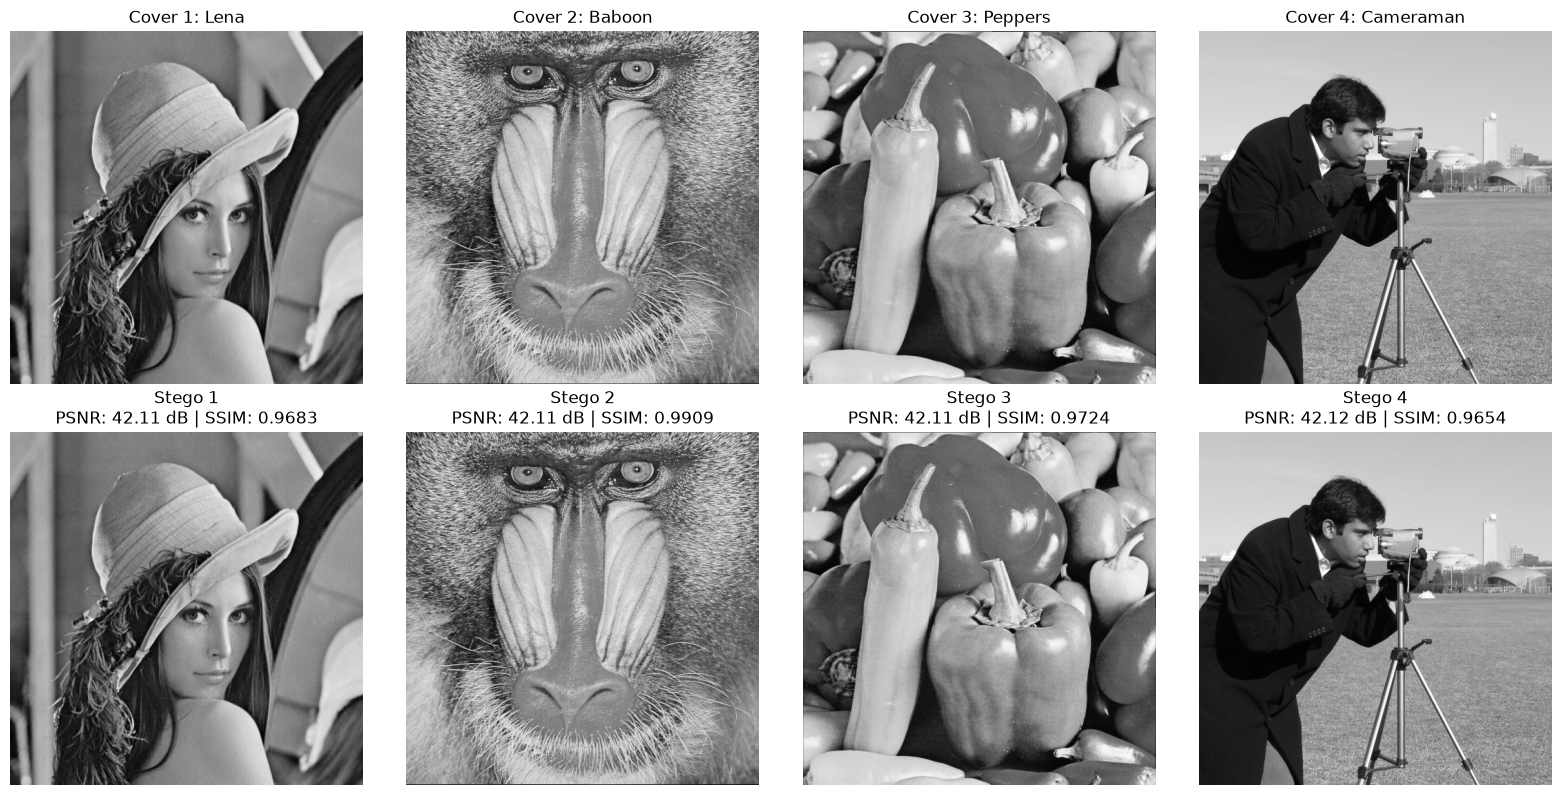

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for i in range(4):
    psnr = compute_psnr(covers[i], stegos[i])
    ssim = compute_ssim(covers[i], stegos[i])
    
    # Original Cover
    axes[0, i].imshow(covers[i], cmap='gray')
    axes[0, i].set_title(f"Cover {i+1}: {carrier_names[i].split('.')[0].capitalize()}")
    axes[0, i].axis('off')
    
    # Stego Image
    axes[1, i].imshow(stegos[i], cmap='gray')
    axes[1, i].set_title(f"Stego {i+1}\nPSNR: {psnr:.2f} dB | SSIM: {ssim:.4f}")
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

### 1.3 The 'Noise' Proof: Magnified 50×50 Residual Heatmap
Visually prove that the spread spectrum signal ($I_{\text{stego}} - I_{\text{cover}}$) mimics zero-mean thermal noise.

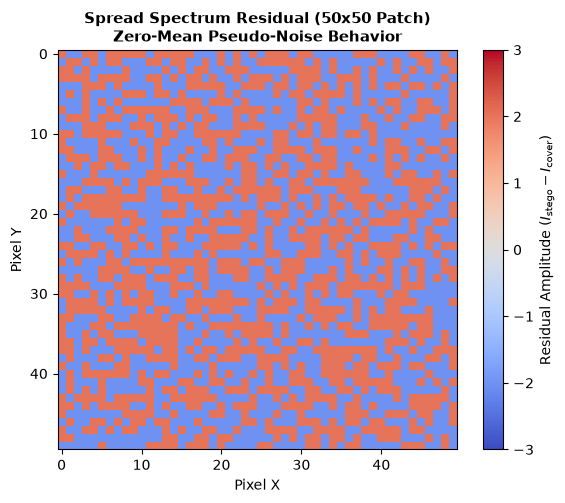

Residual Mean (μ): -0.0083 (Zero-mean noise confirmation)
Residual Std Dev (σ): 1.9997


In [4]:
fig = plot_residual_heatmap(covers[0], stegos[0], patch_size=50)
plt.show()

res = stegos[0].astype(float) - covers[0].astype(float)
print(f"Residual Mean (μ): {np.mean(res):.4f} (Zero-mean noise confirmation)")
print(f"Residual Std Dev (σ): {np.std(res):.4f}")

### 1.4 Blind Correlation Extraction on Clean Stego Images
Regenerate PN sequences from the shared seed key and extract the message.

In [5]:
rec_text, rec_bits, stats = mcss.extract_text(stegos, metadata)
ber_clean = compute_ber(raw_bits, rec_bits)

print(f"Extracted Message: '{rec_text}'")
print(f"Clean Bit Error Rate (BER): {ber_clean * 100:.2f}%")
assert ber_clean == 0.0, "Clean BER should be exactly 0%!"

Extracted Message: 'CONFIDENTIAL: Ruchira ma'am give full marks to this project.'
Clean Bit Error Rate (BER): 0.00%


---
## ⚡ ACT 2: Live Attack & Carrier-Loss Stress Test (4 Minutes)
### 2.1 Missing Carrier Simulation (Catastrophic DSSS Loss vs. MC-SS Fault Tolerance)
Simulate interception or dropping of 1 or 2 carrier images.

In [6]:
# Initialize Single-Image DSSS Baseline on Carrier 0
dsss = SingleImageDSSS(secret_key=secret_key, alpha=alpha)
dsss_stego, dsss_meta = dsss.embed_text(covers[0], secret_text)

# Un-ECC MC-SS for comparison
mcss_no_ecc = MCSSStego(secret_key=secret_key, num_carriers=4, alpha=alpha, use_ecc=False)
stegos_no_ecc, meta_no_ecc = mcss_no_ecc.embed_text(covers, secret_text)

dropped_carriers = [0]  # Drop Carrier 0 (Lena)
print(f"Simulating Dropping Carrier 0 ({carrier_names[0]})...")

# 1. MC-SS with Hamming(7,4) ECC + Interleaving
st_dropped_ecc = simulate_carrier_drop(stegos, dropped_carriers)
txt_ecc, bits_ecc, _ = mcss.extract_text(st_dropped_ecc, metadata, dropped_carriers=dropped_carriers)
ber_ecc = compute_ber(raw_bits, bits_ecc)

# 2. MC-SS without ECC
st_dropped_no = simulate_carrier_drop(stegos_no_ecc, dropped_carriers)
txt_no, bits_no, _ = mcss_no_ecc.extract_text(st_dropped_no, meta_no_ecc, dropped_carriers=dropped_carriers)
ber_no = compute_ber(raw_bits, bits_no)

# 3. Single-Image DSSS (If carrier dropped -> 100% loss)
txt_dsss, bits_dsss = dsss.extract_text(None, dsss_meta)
ber_dsss = 1.0

print("=" * 65)
print(f"1. MC-SS with Hamming ECC BER:  {ber_ecc * 100:.2f}% | Text: '{txt_ecc}'")
print(f"2. MC-SS without ECC BER:       {ber_no * 100:.2f}% | Text: '{txt_no[:35]}...'")
print(f"3. Single-Image DSSS BER:        {ber_dsss * 100:.2f}% | Text: '[TOTAL FAILURE]'")
print("=" * 65)

Simulating Dropping Carrier 0 (lena.png)...
1. MC-SS with Hamming ECC BER:  0.20% | Text: 'CONFIDENTIAL: Ruchira ma'am give full marks to this project.'
2. MC-SS without ECC BER:       8.20% | Text: '...'
3. Single-Image DSSS BER:        100.00% | Text: '[TOTAL FAILURE]'


### 2.2 Channel Distortion: AWGN & JPEG Compression Stress Test

In [7]:
# Additive Gaussian Noise (sigma = 12.0)
noisy_stegos = [apply_gaussian_noise(st, sigma=12.0) for st in stegos]
noisy_dsss = apply_gaussian_noise(dsss_stego, sigma=12.0)

_, bits_mcss_noise, _ = mcss.extract_text(noisy_stegos, metadata)
_, bits_dsss_noise = dsss.extract_text(noisy_dsss, dsss_meta)

print(f"Under AWGN (σ = 12.0):")
print(f" - MC-SS BER: {compute_ber(raw_bits, bits_mcss_noise) * 100:.2f}%")
print(f" - Single DSSS BER: {compute_ber(raw_bits, bits_dsss_noise) * 100:.2f}%")

Under AWGN (σ = 12.0):
 - MC-SS BER: 0.00%
 - Single DSSS BER: 0.00%


### 2.3 Cryptographic Security Proof (Wrong Key Test)

In [8]:
attacker_mcss = MCSSStego(secret_key="AttackerWrongSeed#999", num_carriers=4, alpha=alpha, use_ecc=True)
att_txt, att_bits, _ = attacker_mcss.extract_text(stegos, metadata)
att_ber = compute_ber(raw_bits, att_bits)

print(f"Adversary BER (Unauthorized Key): {att_ber * 100:.2f}%")
print(f"Adversary Output Text: '{att_txt[:50]}...'")

Adversary BER (Unauthorized Key): 46.48%
Adversary Output Text: 'J6К���<V	��4hL>Ї�\O
6`�y�g�Ġ��AU<1��l-�dˠ��k�...'


---
## 📊 ACT 3: Benchmark Graphs & Mentor Defense (2 Minutes)
Display publication-ready evaluation charts.

Graph 1: Imperceptibility vs. Embedding Amplitude (alpha)


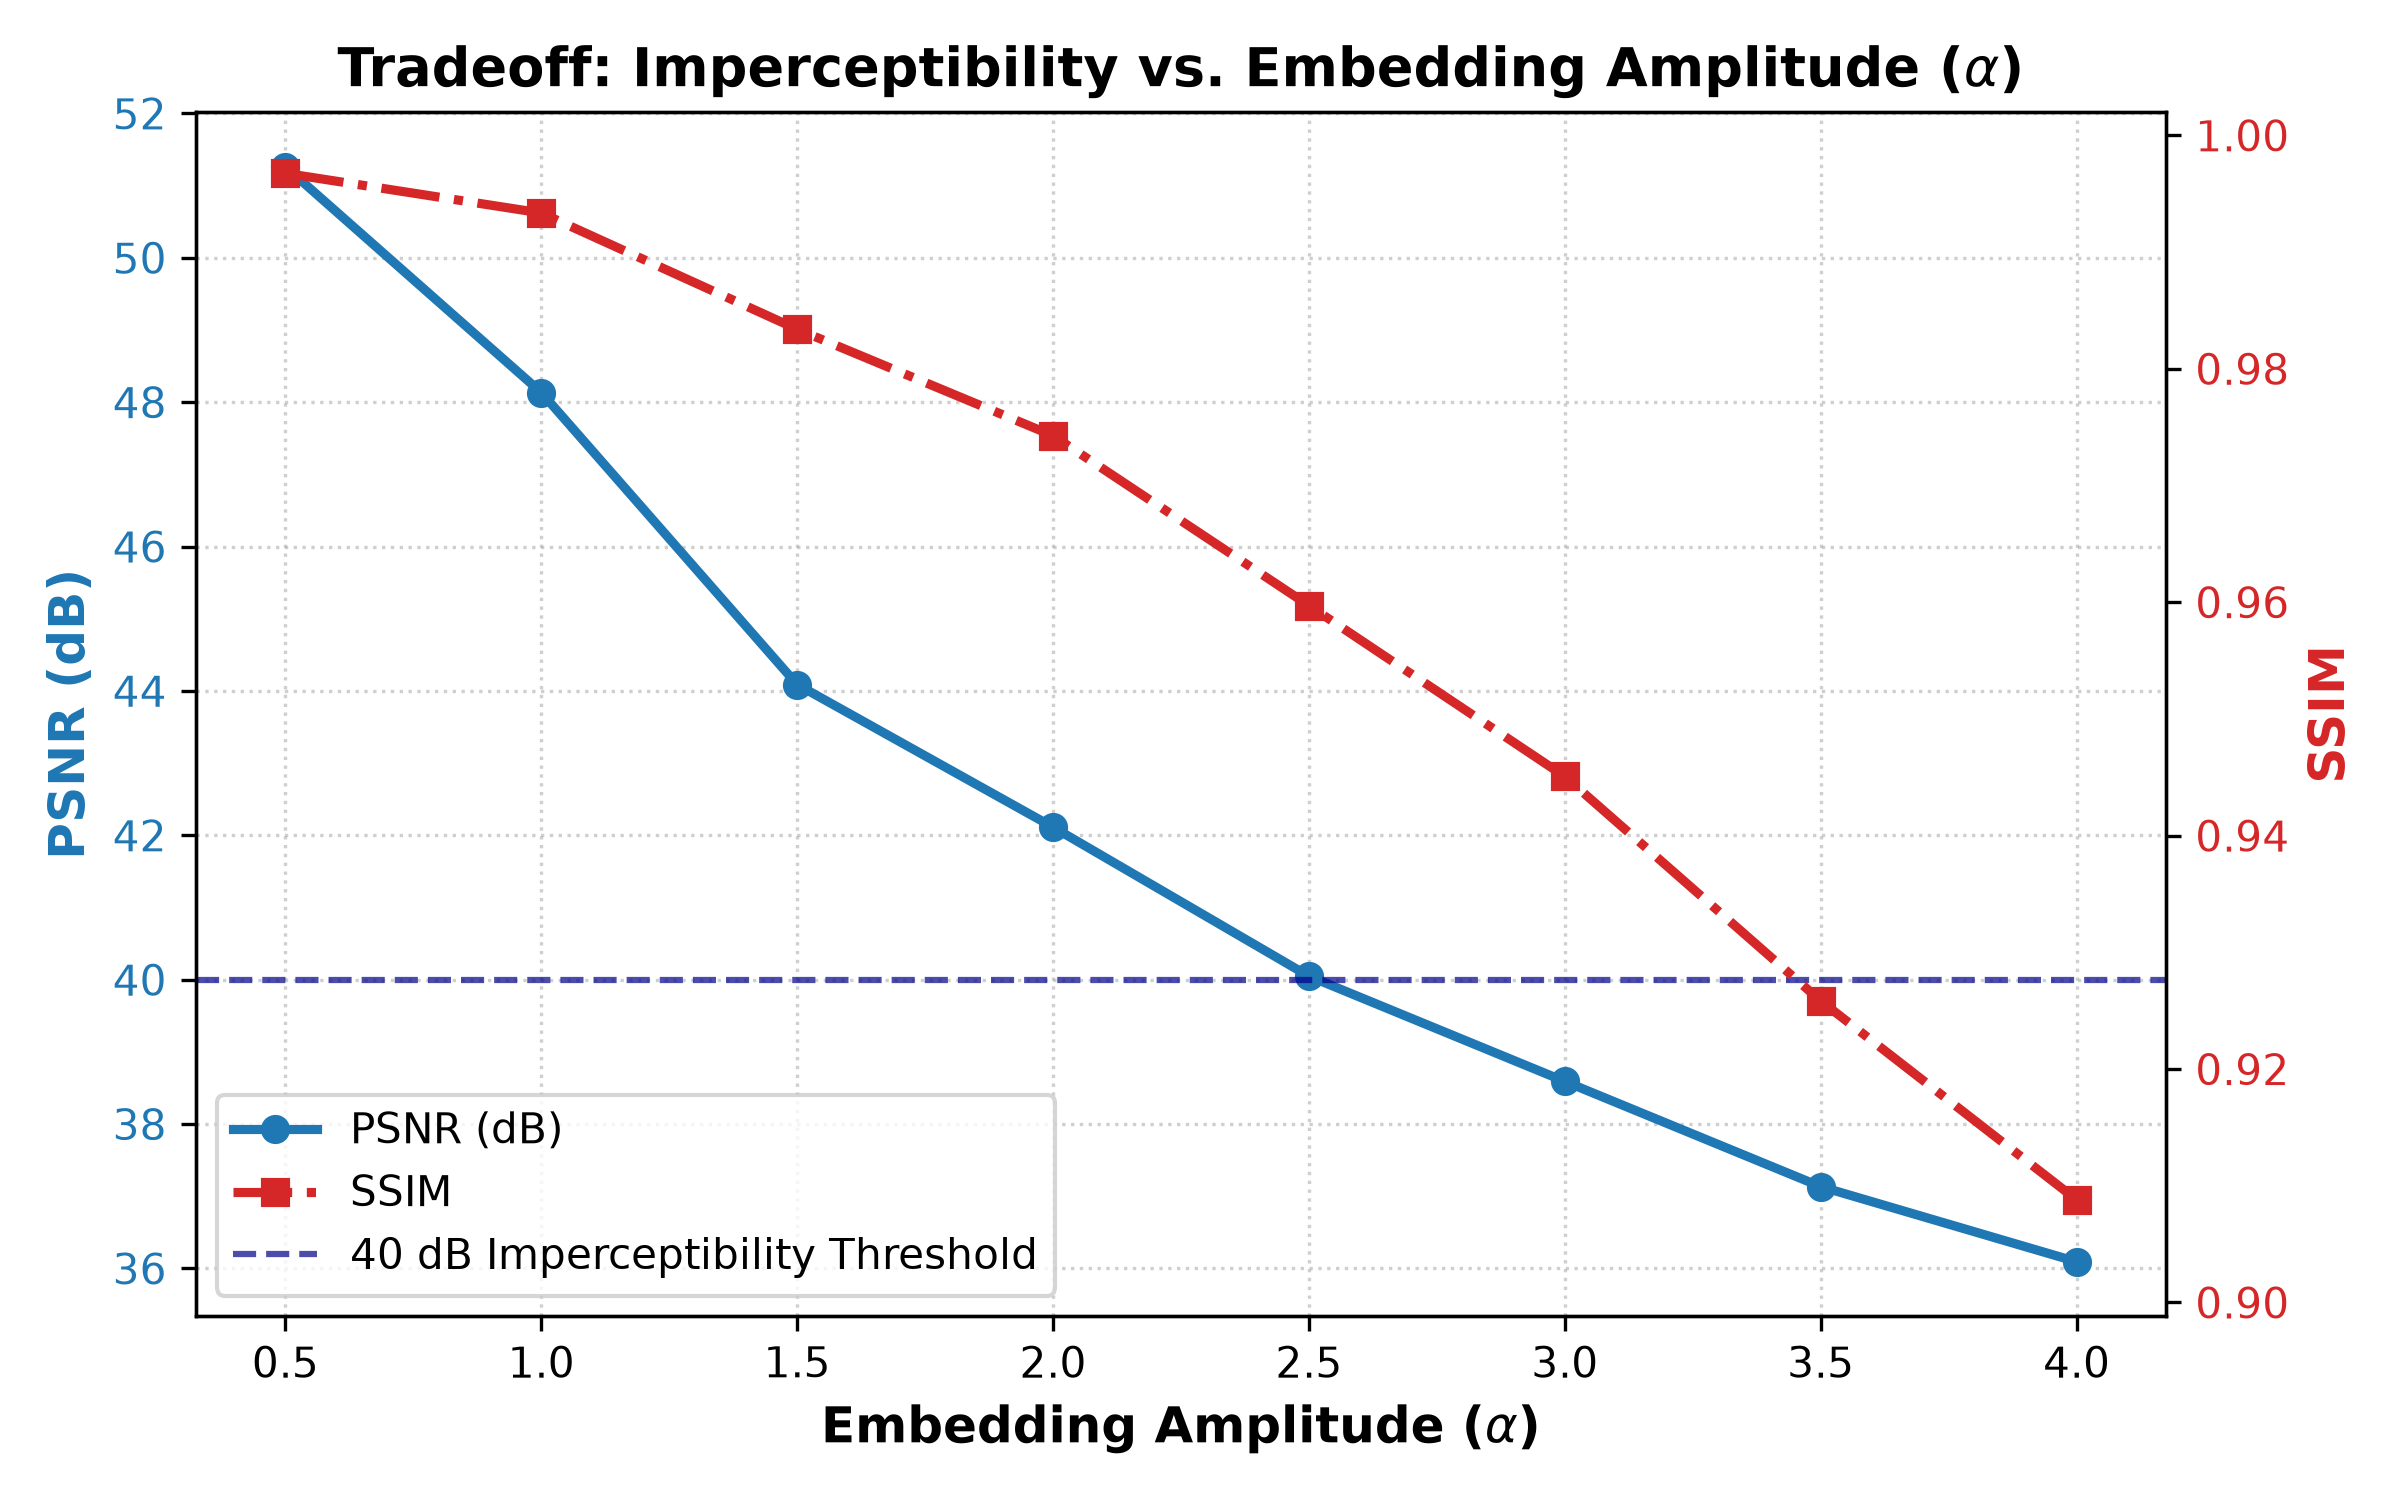

Graph 2: Robustness Curves (AWGN & JPEG)


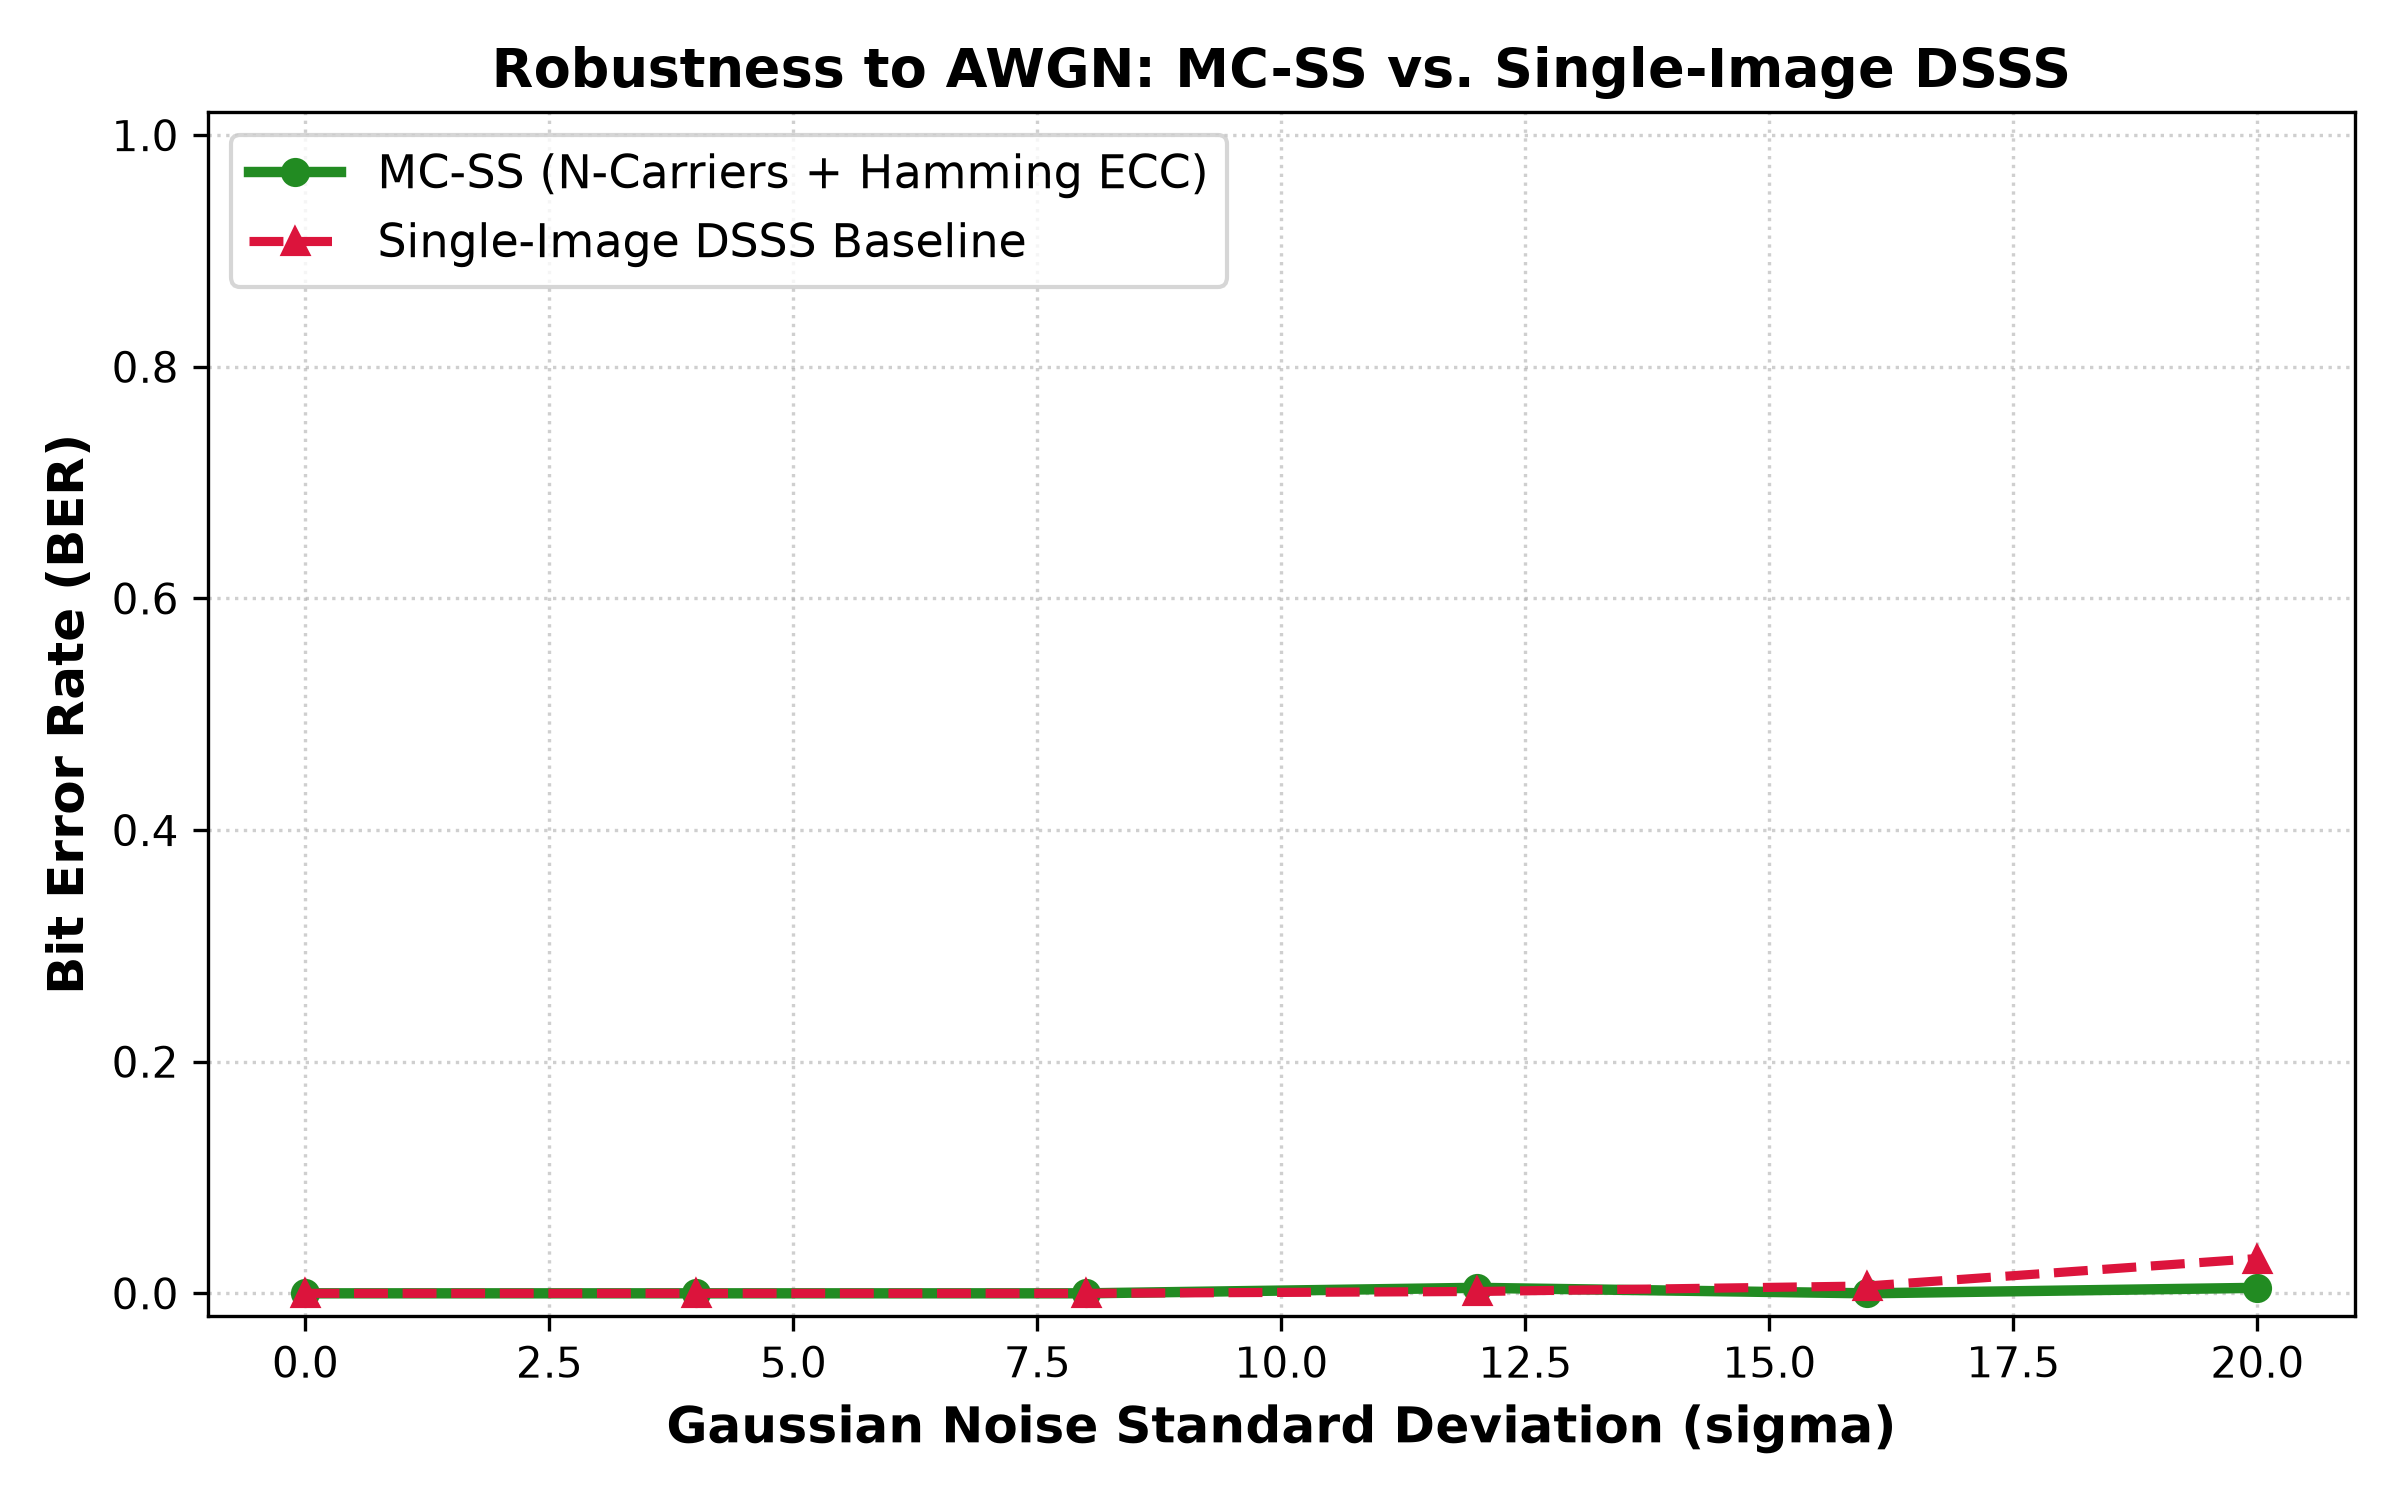

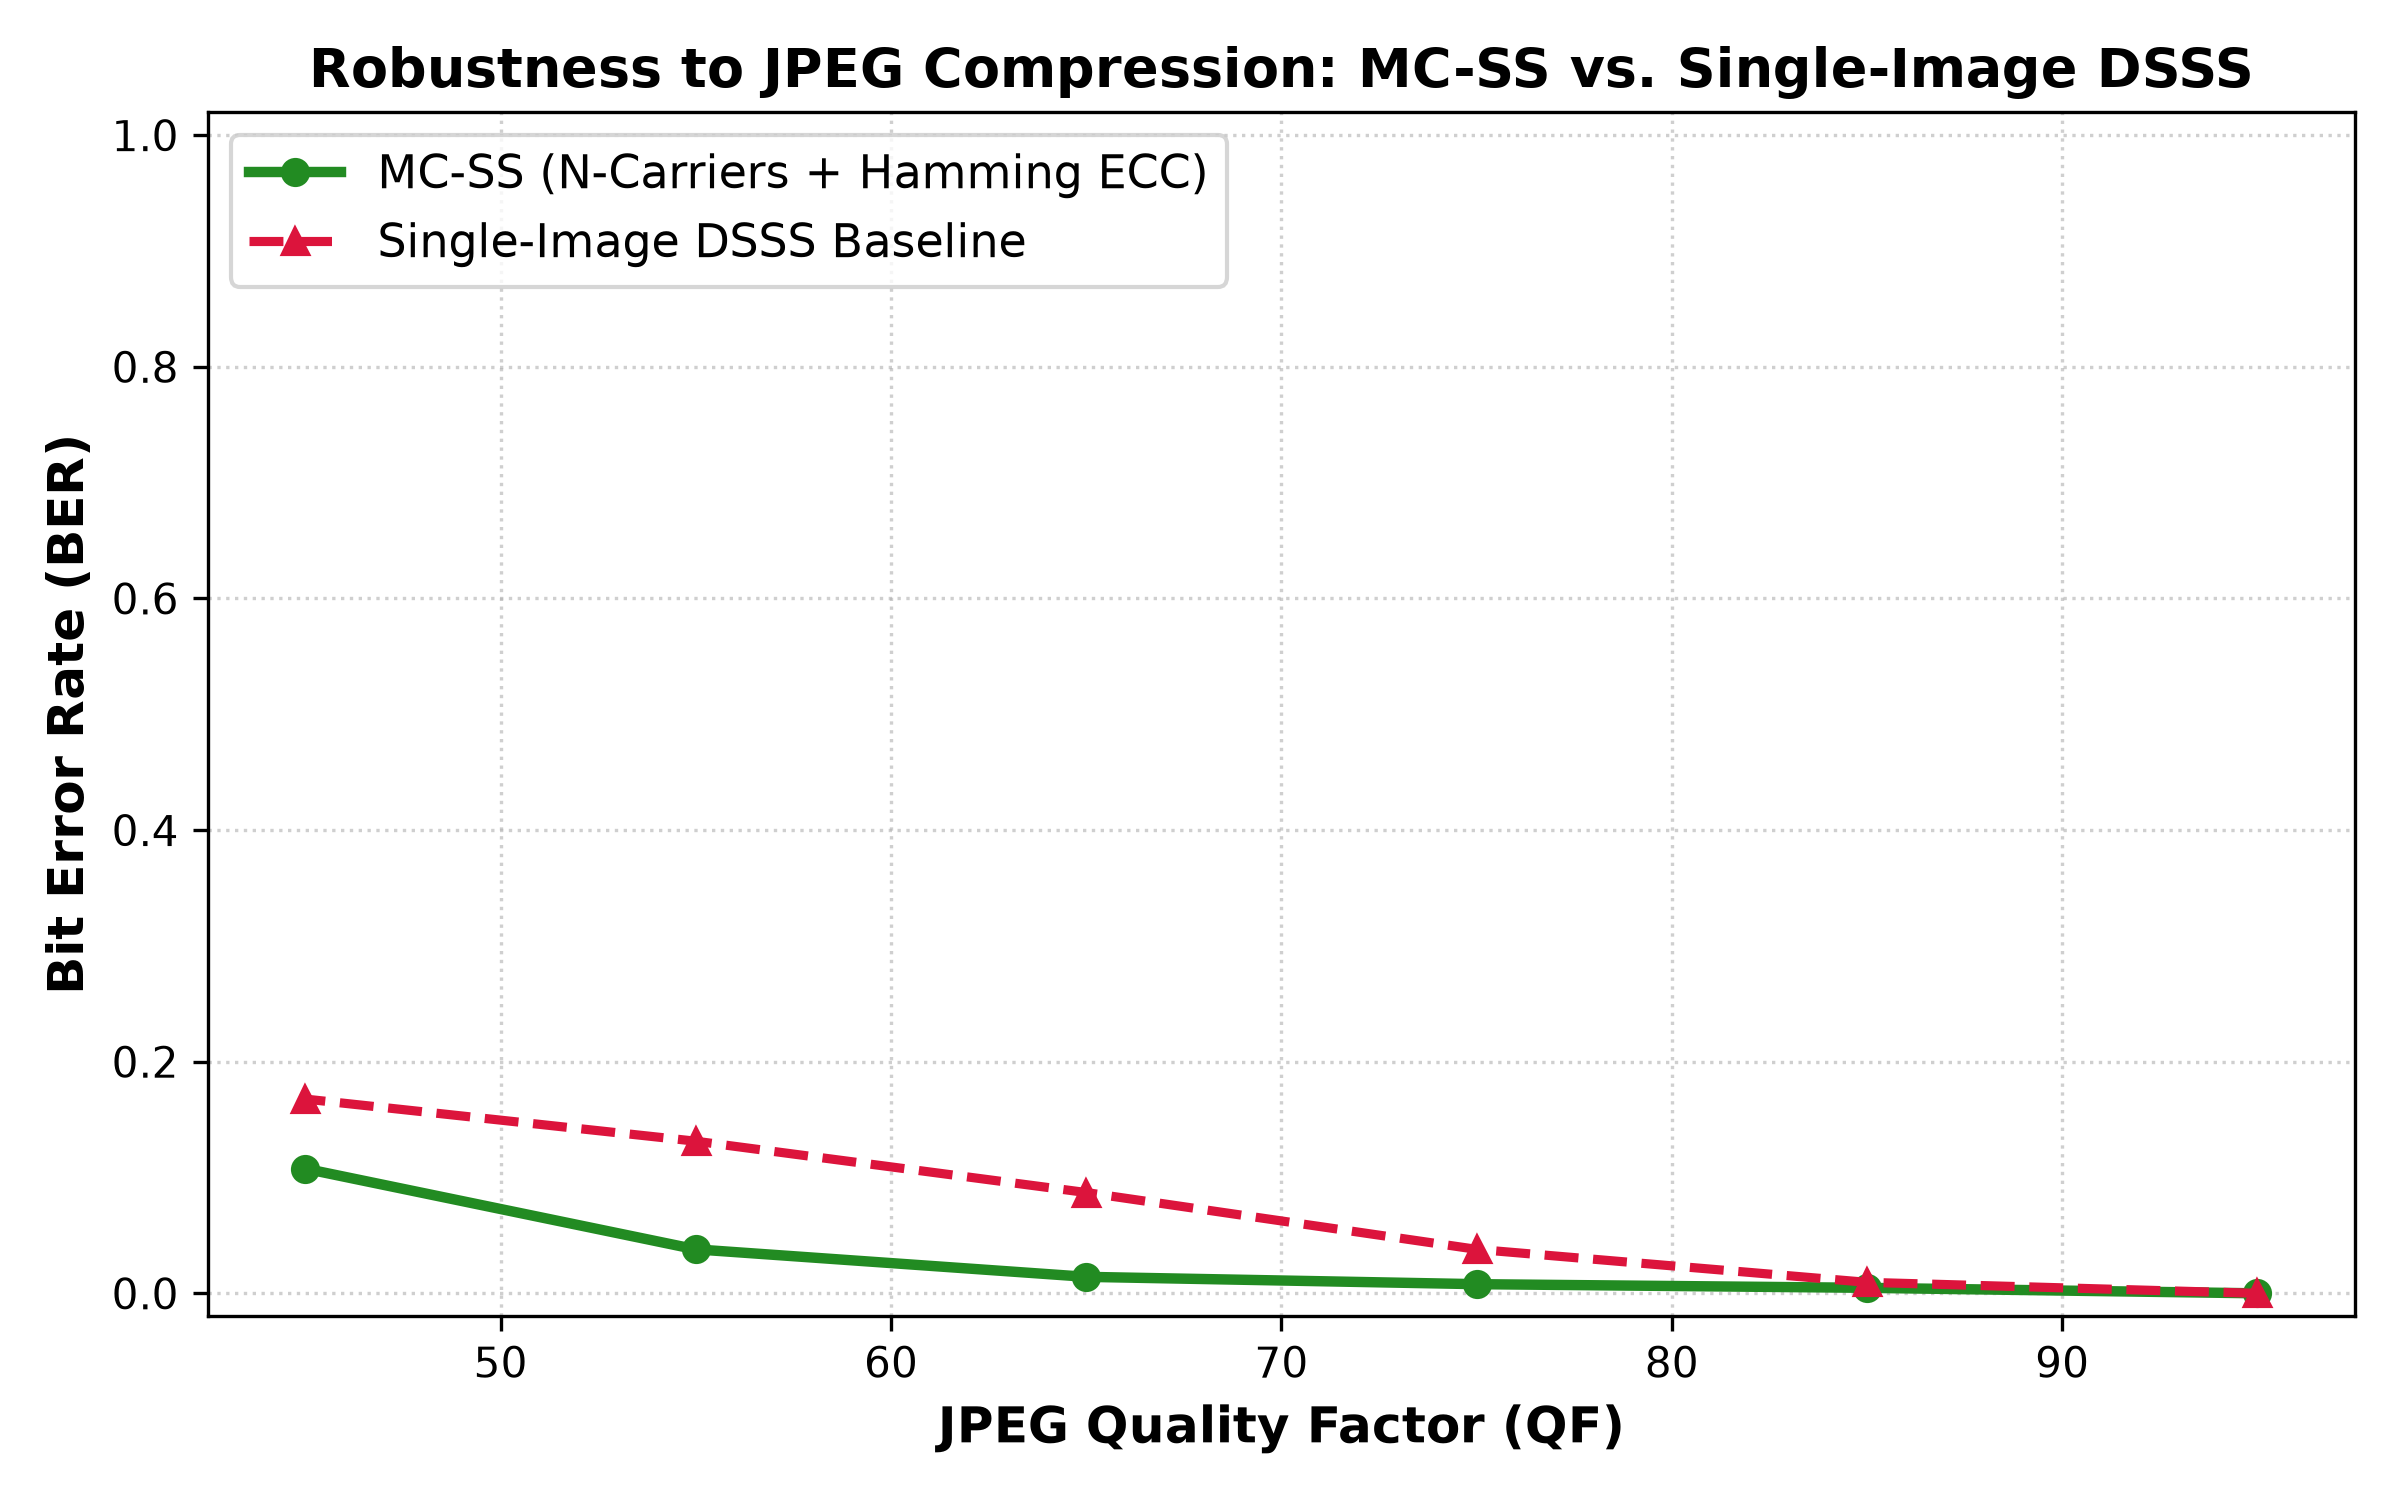

Graph 3: Carrier Loss Resilience


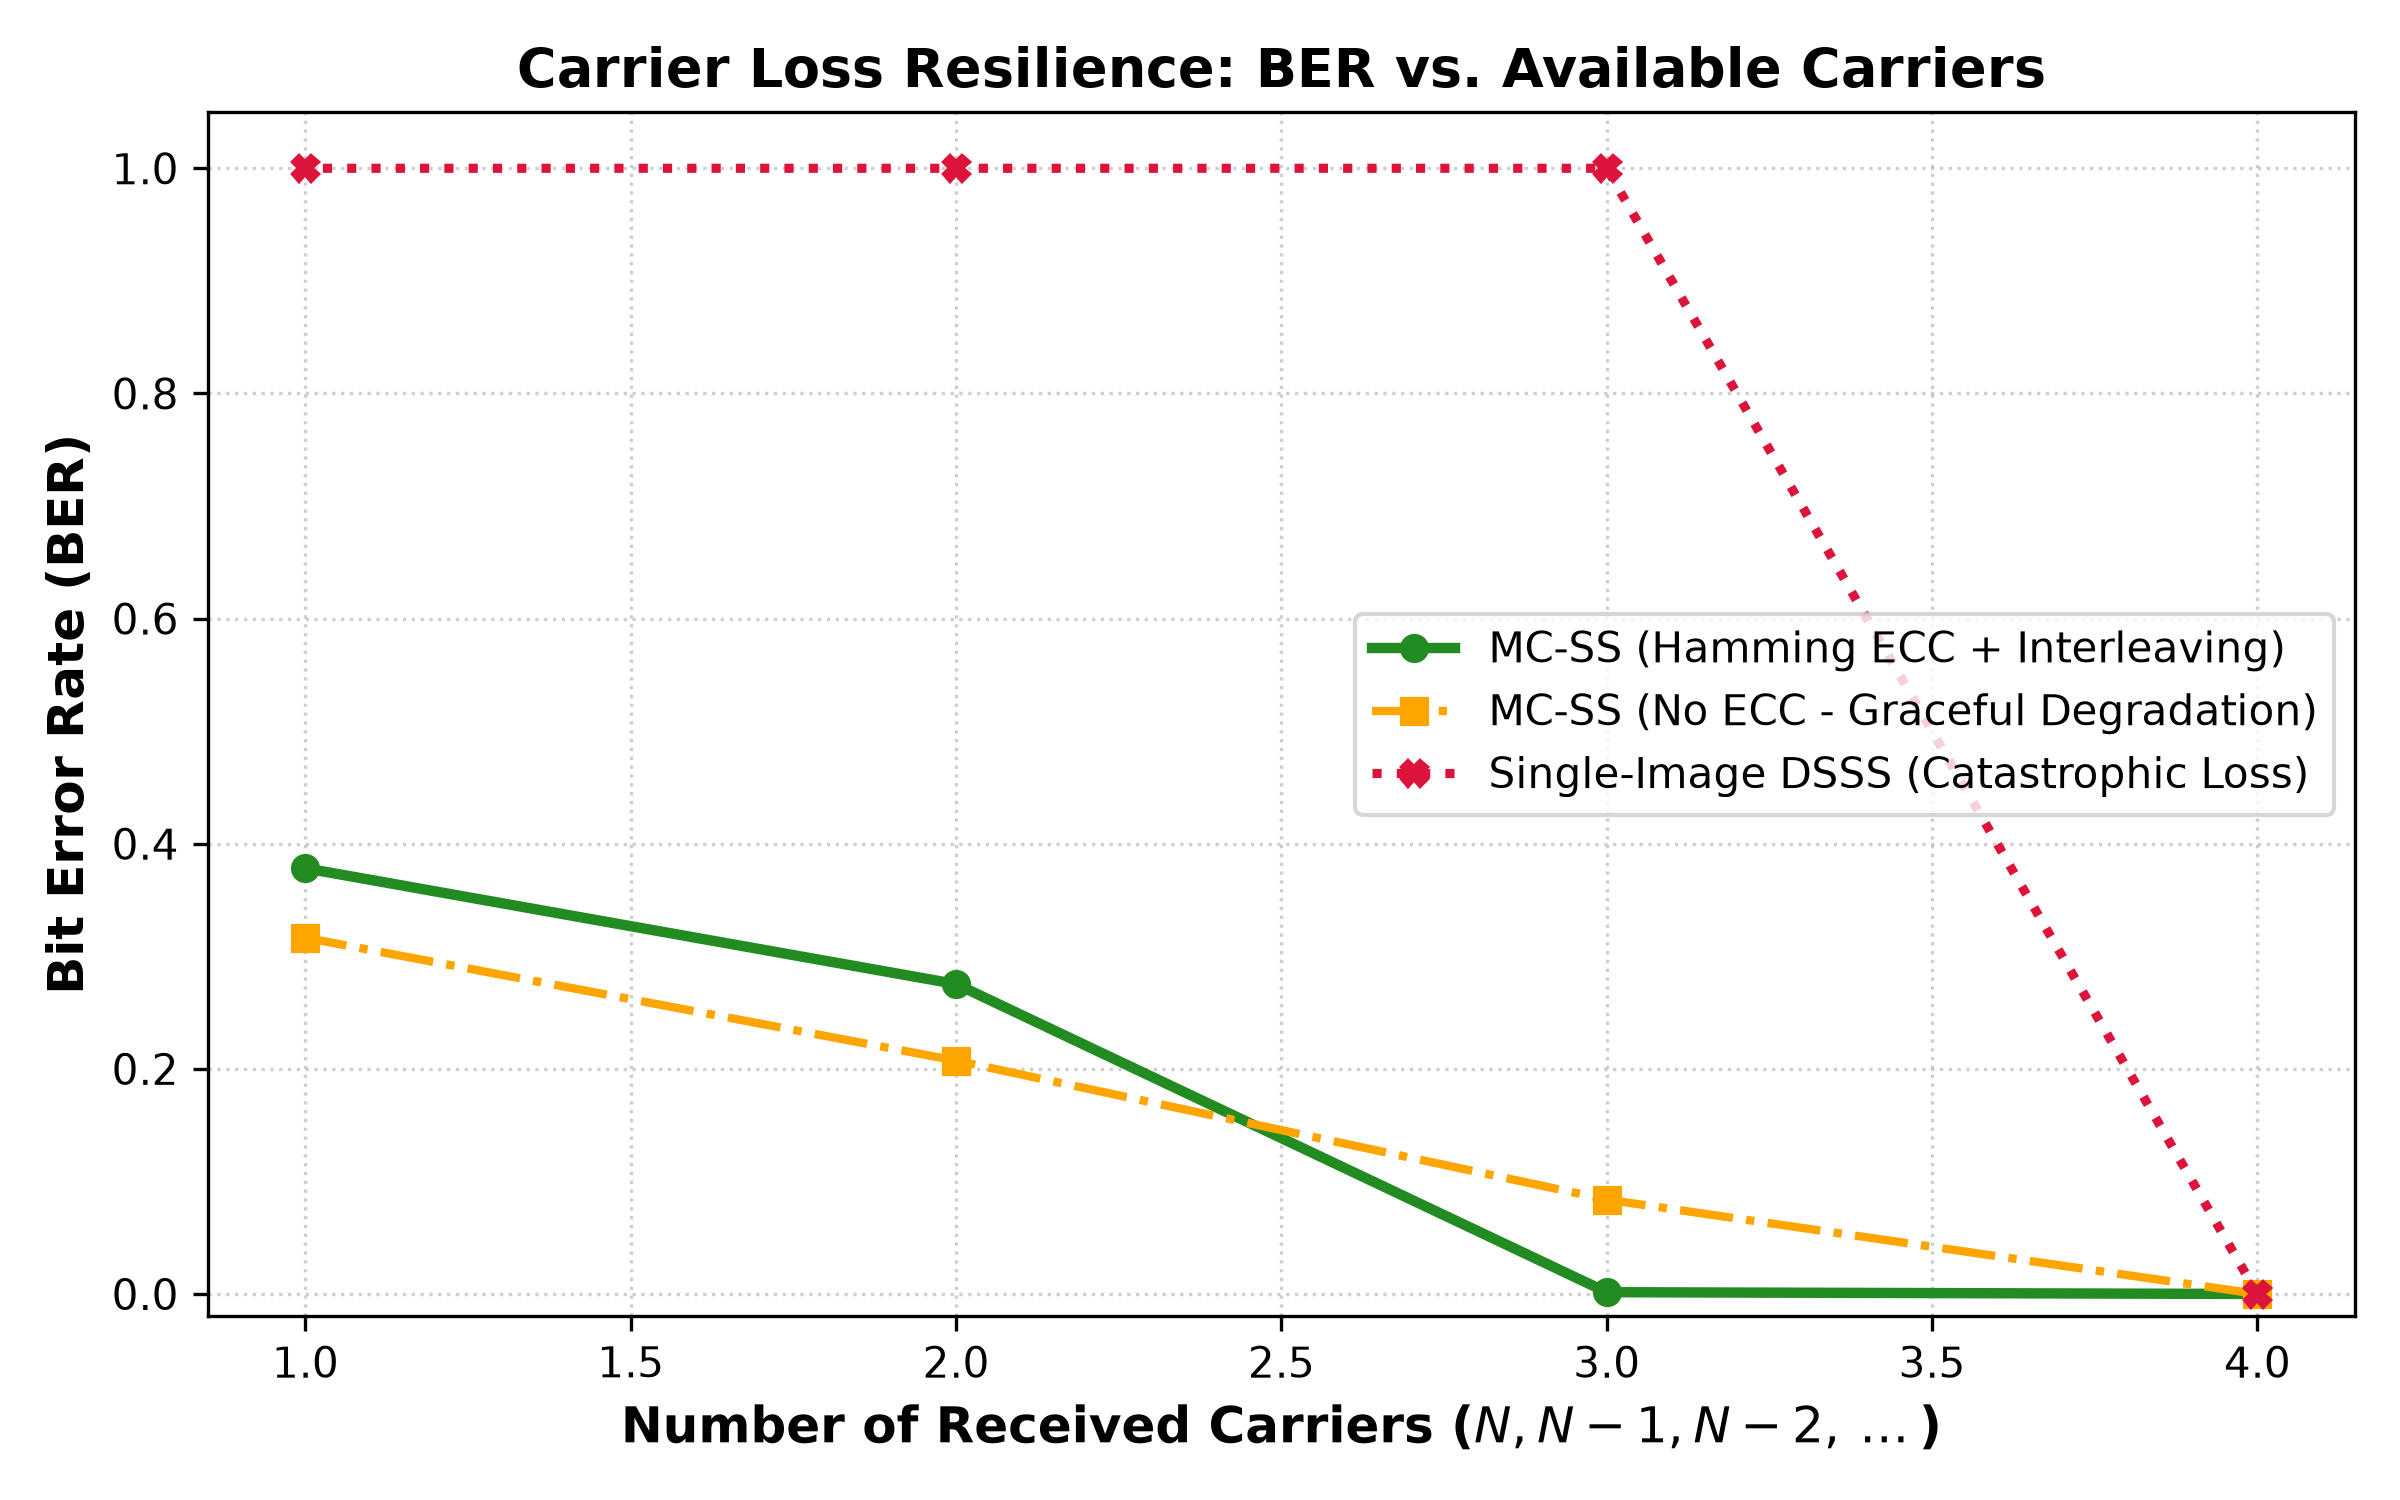

In [9]:
from IPython.display import Image, display

# Run benchmark suite if results are not already generated
if not os.path.exists("results/graph1_psnr_ssim_vs_alpha.png"):
    import run_benchmarks
    run_benchmarks.run_all_benchmarks()

print("Graph 1: Imperceptibility vs. Embedding Amplitude (alpha)")
display(Image("results/graph1_psnr_ssim_vs_alpha.png"))

print("Graph 2: Robustness Curves (AWGN & JPEG)")
display(Image("results/graph2_ber_vs_gaussian_noise.png"))
display(Image("results/graph2b_ber_vs_jpeg.png"))

print("Graph 3: Carrier Loss Resilience")
display(Image("results/graph3_ber_vs_carrier_loss.png"))